In [5]:
import joblib
from pathlib import Path


import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_selection import RFECV

## 1. Data Loading 

In [6]:
dataset = load_breast_cancer(as_frame=True)

df = dataset.frame.copy()

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [7]:
print("Shape:", df.shape)
print("Feature count:", len(dataset.feature_names))
print("Missing values:", df.isna().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Target classes:", dataset.target_names)
print(df["target"].value_counts())

Shape: (569, 31)
Feature count: 30
Missing values: 0
Duplicates: 0
Target classes: ['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


In [8]:
print("Dataframe info:")
print(df.info())
print("=" * 50)

Dataframe info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness

In [9]:
print("Dataframe description:")
print(df.describe())
print("=" * 50)

Dataframe description:
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000           

## 2. Basic Data Cleaning

The dataset is already clean and ready for the exploration stage.

The following cleaning steps were considered:

- Checking for exact duplicate rows.
- Checking for missing values.

The `DateTime` step is skipped because this dataset does not contain any `DateTime` or date-related features.

## 3. Exploratory Data Analysis (EDA)

In [10]:
print("Count:")
print(df["target"].value_counts())

print("\nPercent:")
print((df["target"].value_counts(normalize=True) * 100).round(2))

Count:
target
1    357
0    212
Name: count, dtype: int64

Percent:
target
1    62.74
0    37.26
Name: proportion, dtype: float64


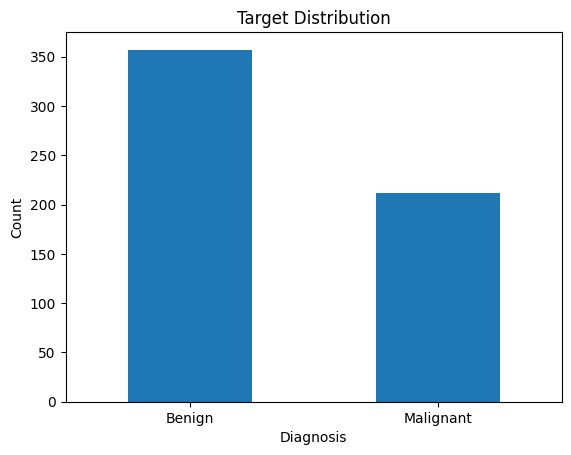

In [11]:
target_mapping = {0: "Malignant", 1: "Benign"}

target_counts = df["target"].map(target_mapping).value_counts()

target_counts.plot(kind="bar")

plt.title("Target Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.xticks(rotation=0)

plt.show()

### EDA Summary — What will guide later preprocessing?

The EDA provides evidence that will guide our preprocessing decisions:

- The numerical features have different distributions and levels of skewness.
- Several features are strongly right-skewed, especially some `error` and `worst` measurements.
- Features with approximately symmetric distributions may be suitable for standard scaling.
- Strongly skewed features may require more robust preprocessing methods.
- Boxplots show potential outliers in several numerical features.
- These extreme values will not be removed automatically because they may represent valid medical observations.
- The dataset contains no missing values after inspection.
- The target variable is binary and represents the classification outcome.
- The target distribution should be considered when evaluating possible class imbalance.
- The numerical features are measured on different scales, so scaling will be important for models such as KNN, SVM, and Logistic Regression.


# 4. Define X and y

In [12]:
x = df.drop(columns=["target"])
y = df["target"]

print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


## 5. Train / Test split

In [13]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)


print("Train:", x_train.shape)
print("Test :", x_test.shape)

print("\nTrain class %:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest class %:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Train: (455, 30)
Test : (114, 30)

Train class %:
target
1    62.64
0    37.36
Name: proportion, dtype: float64

Test class %:
target
1    63.16
0    36.84
Name: proportion, dtype: float64


# 6. Missing values — inspect Training Data first

Before filling anything, check the amount and type of missing data in Training Data.

In [14]:
missing_train = x_train.isna().sum().to_frame("Missing_Count")

missing_train["Missing_%"] = (x_train.isna().mean() * 100).round(2)

missing_train["Data_Type"] = x_train.dtypes.astype(str)

missing_train.sort_values("Missing_%", ascending=False)

,Missing_Count,Missing_%,Data_Type
mean radius,0,0.0,float64
mean texture,0,0.0,float64
mean perimeter,0,0.0,float64
mean area,0,0.0,float64
mean smoothness,0,0.0,float64
mean compactness,0,0.0,float64
mean concavity,0,0.0,float64
mean concave points,0,0.0,float64
mean symmetry,0,0.0,float64
mean fractal dimension,0,0.0,float64


## 7. Outliers — diagnose every numerical feature

In [15]:
# Outlier analysis on training data only

numeric_check_cols = x_train.columns

for col in numeric_check_cols:
    data = x_train[col]

    # IQR method
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_outliers = ((data < lower) | (data > upper)).sum()

    # Z-score method
    z = ((data - data.mean()) / data.std()).abs()
    z_outliers = (z > 3).sum()

    print("\n", col)
    print("Skewness:", round(data.skew(), 3))
    print("IQR outliers:", iqr_outliers)
    print("Z > 3:", z_outliers)
    print("Min:", round(data.min(), 2))
    print("Max:", round(data.max(), 2))


 mean radius
Skewness: 0.917
IQR outliers: 12
Z > 3: 4
Min: 6.98
Max: 28.11

 mean texture
Skewness: 0.723
IQR outliers: 7
Z > 3: 4
Min: 9.71
Max: 39.28

 mean perimeter
Skewness: 0.967
IQR outliers: 13
Z > 3: 5
Min: 43.79
Max: 188.5

 mean area
Skewness: 1.539
IQR outliers: 24
Z > 3: 8
Min: 143.5
Max: 2499.0

 mean smoothness
Skewness: 0.396
IQR outliers: 5
Z > 3: 4
Min: 0.06
Max: 0.14

 mean compactness
Skewness: 1.251
IQR outliers: 14
Z > 3: 8
Min: 0.02
Max: 0.35

 mean concavity
Skewness: 1.385
IQR outliers: 15
Z > 3: 6
Min: 0.0
Max: 0.43

 mean concave points
Skewness: 1.181
IQR outliers: 8
Z > 3: 4
Min: 0.0
Max: 0.2

 mean symmetry
Skewness: 0.773
IQR outliers: 14
Z > 3: 5
Min: 0.11
Max: 0.3

 mean fractal dimension
Skewness: 1.31
IQR outliers: 13
Z > 3: 6
Min: 0.05
Max: 0.1

 radius error
Skewness: 2.966
IQR outliers: 37
Z > 3: 8
Min: 0.11
Max: 2.87

 texture error
Skewness: 1.749
IQR outliers: 18
Z > 3: 5
Min: 0.36
Max: 4.88

 perimeter error
Skewness: 3.371
IQR outliers: 33
Z

In [20]:
selector_model = LogisticRegression(random_state=42)

In [21]:
selector = RFECV(
    estimator=selector_model,
    cv=5,
    scoring="accuracy",
)

In [22]:
selector.fit(x_train, y_train)

h:\Route\ML_Task1_p1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
h:\Route\ML_Task1_p1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please als

,estimator,LogisticRegre...ndom_state=42)
,step,1
,min_features_to_select,1
,cv,5
,scoring,'accuracy'
,verbose,0
,n_jobs,None
,importance_getter,'auto'
,penalty,'l2'
,dual,False
,tol,0.0001


In [23]:
selector.n_features_

np.int64(8)

In [24]:
selected_features = x_train.columns[selector.support_]
selected_features

Index(['mean radius', 'mean concavity', 'mean concave points', 'radius error',
       'worst perimeter', 'worst concavity', 'worst concave points',
       'worst symmetry'],
      dtype='object')

## 8. Preprocess and train using a Pipeline

In [16]:
model_pipeline = Pipeline(
    [("scaler", StandardScaler()), ("model", LogisticRegression(random_state=42))]
)

model_pipeline.fit(x_train, y_train)
print("Model trained")

Model trained


### 8.1 Verify Scaling

In [17]:
scaler = model_pipeline.named_steps["scaler"]

x_train_scaled = scaler.transform(x_train)

print("Mean:", x_train_scaled.mean(axis=0).round(2))
print("Std:", x_train_scaled.std(axis=0).round(2))

Mean: [-0.  0. -0. -0.  0. -0. -0.  0. -0.  0. -0. -0.  0.  0. -0. -0.  0. -0.
  0.  0.  0. -0. -0.  0.  0. -0.  0. -0. -0.  0.]
Std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


## 9. Model Evaluation

In [18]:
y_pred = model_pipeline.predict(x_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

Accuracy: 0.9825
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## 13. Save the trained Pipeline

In [19]:
model_path = Path("../models/pipeline.joblib")  # When notebook runs inside notebooks/
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model_pipeline, model_path)

loaded_model = joblib.load(model_path)
sample = x_test.iloc[[0]]
print("Prediction:", loaded_model.predict(sample)[0])
print("Actual:", y_test.iloc[0])

Prediction: 0
Actual: 0
